## **NAMA : MUHAMAD ALFA REZA GOBEL**
## **NIM  : 23031554207**
## **UTS  : GRAF SAINS DATA (2023B)**

## **PENDAHULUAN**

#### **Environment**

In [1]:
import sys
import os

ENV_PATH = r"D:/TUGAS KAMPUS SEMESTER 7/GRAF SAINS DATA/UTS GRAF SAINS DATA/myenv"
PYTHON_ENV = os.path.join(ENV_PATH, "Scripts", "python.exe")

print("Folder environment tersedia:", os.path.isdir(ENV_PATH))
print("Python environment tersedia:", os.path.isfile(PYTHON_ENV))
print("Path Python aktif:", sys.executable)

Folder environment tersedia: True
Python environment tersedia: True
Path Python aktif: c:\Users\lenovo\AppData\Local\Programs\Python\Python312\python.exe


#### **Requirements.txt**

proses di powershell : uv pip install -r requirements.txt 

In [2]:
REQUIREMENTS_PATH = r"D:/TUGAS KAMPUS SEMESTER 7/GRAF SAINS DATA/UTS GRAF SAINS DATA/requirements.txt"

with open(REQUIREMENTS_PATH, "r", encoding="utf-8") as file:
    print(file.read())

neo4j>=4.0,<4.3
imdbpy==2020.9.25
nose==1.3.7
cinemagoerng>=0.4
imdbinfo>=0.5
imdbpy>=2020.9.25
neo4j==4.2.1


#### **String koneksi ke database Neo4J**

In [3]:
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
AUTH = ("neo4j", "REZAUTSGSD2026")

In [4]:
def add_friend(driver, name, friend_name):
    with driver.session(database="neo4j") as session:
        session.run(
            "MERGE (a:Person {name: $name}) "
            "MERGE (friend:Person {name: $friend_name}) "
            "MERGE (a)-[:KNOWS]->(friend)",
            name=name,
            friend_name=friend_name
        )

In [5]:
def print_friends(driver, name):
    with driver.session(database="neo4j") as session:
        result = session.run(
            "MATCH (a:Person)-[:KNOWS]->(friend) "
            "WHERE a.name = $name "
            "RETURN friend.name AS friend_name "
            "ORDER BY friend.name",
            name=name
        )

        for record in result:
            print(record["friend_name"])

In [6]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()

    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")

    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


#### **Pertanyaan dan Jawaban Pendahuluan :**

**Apa nama database yang digunakan pada tutorial ini?**

Nama database yang digunakan adalah neo4j, sesuai dengan parameter session(database="neo4j") pada kode main.py.

**Sebutkan akses lain (seperti sintaks DDL/DML Cypher) yang dapat digunakan mengakses database lain dalam satu instance!**

Database lain dalam satu instance Neo4j dapat diakses dengan menentukan nama database pada parameter session(database="nama_database"). Selain itu, Cypher dapat digunakan untuk mengelola data graf melalui perintah seperti MERGE untuk membuat node dan relasi jika belum ada, serta MATCH untuk mencari data.

**Apa jenis graf pertemanan yang telah dibuat di sini?**

Graf pertemanan yang dibuat adalah graf berarah (directed graph), karena relasi KNOWS memiliki arah dari node Person yang bernama Arthur menuju node teman-temannya, yaitu Guinevere, Lancelot, dan Merlin.

###  **Impor Data dari RetailRocket ke Database Neo4J**

Proses impor dataset RetailRocket ke dalam database Neo4j dilakukan melalui PowerShell dengan menjalankan file import_retailrocket.py. Script tersebut digunakan untuk membaca dataset dari file CSV, membentuk node Visitor dan Item, serta membuat relasi interaksi berdasarkan jenis event, yaitu VIEWED, ADDED_TO_CART, dan BOUGHT.

Proses impor dijalankan melalui PowerShell agar seluruh data dapat dimasukkan secara bertahap menggunakan mekanisme batch processing. Setelah proses impor selesai, data graf dapat diakses dan dianalisis melalui Jupyter Notebook menggunakan koneksi Neo4j.

In [7]:
PY_FILE = r"D:/TUGAS KAMPUS SEMESTER 7/GRAF SAINS DATA/UTS GRAF SAINS DATA/import_retailrocket.py"

with open(PY_FILE, "r", encoding="utf-8") as file:
    print(file.read())


import argparse
import os
import sys
import math

import pandas as pd
from tqdm import tqdm
from neo4j import GraphDatabase


def parse_arguments():
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket ke Neo4j."
    )
    parser.add_argument("-u", "--user", default="neo4j")
    parser.add_argument("-p", "--password", default="REZAUTSGSD2026")
    parser.add_argument(
        "-b", "--bolt", default="bolt://127.0.0.1:7687"
    )
    parser.add_argument("-s", "--source", default="retailrocket")
    parser.add_argument("--batch-size", type=int, default=1000)
    return parser.parse_args()

# ADA PENYESUAIAN
def create_constraints(session):
    session.run(
        "CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS "
        "FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE"
    )
    session.run(
        "CREATE CONSTRAINT item_id_unique IF NOT EXISTS "
        "FOR (i:Item) REQUIRE i.itemId IS UNIQUE"
    )


def import_batch(tx, batch):
    cypher_query =

In [8]:
import pandas as pd
FILE_PATH = r"D:/TUGAS KAMPUS SEMESTER 7/GRAF SAINS DATA/UTS GRAF SAINS DATA/retailrocket/events.csv"

df = pd.read_csv(FILE_PATH)

print("EDA DATASET RETAILROCKET")
print("=" * 40)
print(f"Jumlah baris       : {df.shape[0]:,}")
print(f"Jumlah kolom       : {df.shape[1]}")
print(f"Ukuran file        : {os.path.getsize(FILE_PATH) / (1024**2):.2f} MB")
print(f"Jumlah data duplikat: {df.duplicated().sum():,}")

display(df.head())

EDA DATASET RETAILROCKET
Jumlah baris       : 2,756,101
Jumlah kolom       : 5
Ukuran file        : 89.87 MB
Jumlah data duplikat: 460


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [9]:
ringkasan = pd.DataFrame({
    "Tipe Data": df.dtypes.astype(str),
    "Jumlah Kosong": df.isna().sum(),
    "Jumlah Unik": df.nunique()
})

display(ringkasan)

,Tipe Data,Jumlah Kosong,Jumlah Unik
timestamp,int64,0,2750455
visitorid,int64,0,1407580
event,object,0,3
itemid,int64,0,235061
transactionid,float64,2733644,17672


In [10]:
print("DISTRIBUSI EVENT")
display(
    df["event"].value_counts()
      .rename_axis("Jenis Event")
      .reset_index(name="Jumlah")
)

print("JUMLAH VISITOR UNIK:", f"{df['visitorid'].nunique():,}")
print("JUMLAH ITEM UNIK:", f"{df['itemid'].nunique():,}")
print("JUMLAH TRANSAKSI UNIK:", f"{df['transactionid'].nunique():,}")
print("JUMLAH TRANSACTIONID KOSONG:", f"{df['transactionid'].isna().sum():,}")

DISTRIBUSI EVENT


,Jenis Event,Jumlah
0,view,2664312
1,addtocart,69332
2,transaction,22457


JUMLAH VISITOR UNIK: 1,407,580
JUMLAH ITEM UNIK: 235,061
JUMLAH TRANSAKSI UNIK: 17,672
JUMLAH TRANSACTIONID KOSONG: 2,733,644


## **WRANGLING & EDA**

####  **Soal 2.1 (No.1 - 2) Periode Waktu sebagai Filter dari Data Interaksi**

Fold Training = 6/5/2015 - 8/5/2015 | Fold Test = 8/14/2015- 8/29/2015

In [11]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(Path("retailrocket/events.csv"))

df["datetime"] = pd.to_datetime(
    df["timestamp"], unit="ms", errors="coerce"
)

# Periode training: 5 Juni–5 Agustus 2015
training_mulai = "2015-06-05"
training_akhir = "2015-08-05"

# Periode testing: 14–29 Agustus 2015
testing_mulai = "2015-08-14"
testing_akhir = "2015-08-29"

In [12]:
data_training = df[
    (df["datetime"] >= pd.Timestamp(training_mulai)) &
    (df["datetime"] < pd.Timestamp(training_akhir) + pd.Timedelta(days=1))
].copy()

data_testing = df[
    (df["datetime"] >= pd.Timestamp(testing_mulai)) &
    (df["datetime"] < pd.Timestamp(testing_akhir) + pd.Timedelta(days=1))
].copy()

data_training.to_csv("P(1)_training.csv", index=False)
data_testing.to_csv("P(2)_testing.csv", index=False)

print("Rentang training:", data_training["datetime"].min(), "hingga", data_training["datetime"].max())
print("Rentang testing:", data_testing["datetime"].min(), "hingga", data_testing["datetime"].max())
print("Jumlah data training:", len(data_training))
print("Jumlah data testing:", len(data_testing))

Rentang training: 2015-06-05 00:00:03.164000 hingga 2015-08-05 23:59:55.803000
Rentang testing: 2015-08-14 00:00:00.927000 hingga 2015-08-29 23:59:40.111000
Jumlah data training: 1308645
Jumlah data testing: 283347


In [13]:
print("DUPLIKASI DATA TRAINING")
print("Jumlah baris duplikat:", data_training.duplicated().sum())

print("\nDUPLIKASI DATA TESTING")
print("Jumlah baris duplikat:", data_testing.duplicated().sum())

DUPLIKASI DATA TRAINING
Jumlah baris duplikat: 228

DUPLIKASI DATA TESTING
Jumlah baris duplikat: 63


In [14]:
duplikat_training = data_training[
    data_training.duplicated(keep=False)
].sort_values(["timestamp", "visitorid", "itemid"])

duplikat_testing = data_testing[
    data_testing.duplicated(keep=False)
].sort_values(["timestamp", "visitorid", "itemid"])

print("DUPLIKAT IDENTIK DATA TRAINING")
print("Jumlah baris:", data_training.duplicated().sum())
display(duplikat_training)

print("DUPLIKAT IDENTIK DATA TESTING")
print("Jumlah baris:", data_testing.duplicated().sum())
display(duplikat_testing)

DUPLIKAT IDENTIK DATA TRAINING
Jumlah baris: 228


,timestamp,visitorid,event,itemid,transactionid,datetime
71466,1433463640728,497546,addtocart,278319,NaN,2015-06-05 00:20:40.728
75063,1433463640728,497546,addtocart,278319,NaN,2015-06-05 00:20:40.728
83143,1433463912411,263168,addtocart,436219,NaN,2015-06-05 00:25:12.411
87304,1433463912411,263168,addtocart,436219,NaN,2015-06-05 00:25:12.411
82954,1433475871737,1159733,addtocart,104116,NaN,2015-06-05 03:44:31.737
...,...,...,...,...,...,...
683276,1438721406222,1303048,addtocart,170859,NaN,2015-08-04 20:50:06.222
666645,1438749886852,691253,addtocart,465750,NaN,2015-08-05 04:44:46.852
676191,1438749886852,691253,addtocart,465750,NaN,2015-08-05 04:44:46.852
686021,1438759281741,1063228,addtocart,96680,NaN,2015-08-05 07:21:21.741


DUPLIKAT IDENTIK DATA TESTING
Jumlah baris: 63


,timestamp,visitorid,event,itemid,transactionid,datetime
827839,1439516742696,110597,addtocart,269953,NaN,2015-08-14 01:45:42.696
836869,1439516742696,110597,addtocart,269953,NaN,2015-08-14 01:45:42.696
841131,1439516825163,110597,addtocart,159184,NaN,2015-08-14 01:47:05.163
845260,1439516825163,110597,addtocart,159184,NaN,2015-08-14 01:47:05.163
827865,1439516840787,110597,addtocart,220858,NaN,2015-08-14 01:47:20.787
...,...,...,...,...,...,...
1104155,1440811066346,488349,addtocart,451373,NaN,2015-08-29 01:17:46.346
1107722,1440817610810,366075,view,448736,NaN,2015-08-29 03:06:50.810
1111047,1440817610810,366075,view,448736,NaN,2015-08-29 03:06:50.810
1119692,1440853880655,1355680,addtocart,441343,NaN,2015-08-29 13:11:20.655


In [15]:
kolom = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid",
    "datetime"
]

display(
    data_training.loc[
        [71466, 75063], kolom
    ]
)

,timestamp,visitorid,event,itemid,transactionid,datetime
71466,1433463640728,497546,addtocart,278319,NaN,2015-06-05 00:20:40.728
75063,1433463640728,497546,addtocart,278319,NaN,2015-06-05 00:20:40.728


In [16]:
data_training = data_training.drop_duplicates().copy()
data_testing = data_testing.drop_duplicates().copy()

In [17]:
print("Duplikat training:", data_training.duplicated().sum())
print("Duplikat testing:", data_testing.duplicated().sum())

Duplikat training: 0
Duplikat testing: 0


#### **Soal 2.1 (No.3) Komposisi dari Subgraph yang Dibuat**

In [18]:

import pandas as pd
from getpass import getpass
from neo4j import GraphDatabase

URI = "bolt://127.0.0.1:7687"
USER = "neo4j"
PASSWORD = "REZAUTSGSD2026"
DATABASE = "retailrocket"

periode_subgraph = {
    "Training": ("2015-06-05", "2015-08-06"),
    "Testing": ("2015-08-14", "2015-08-30")
}

query = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS jumlah_interaksi
"""

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
hasil_komposisi = []

try:
    with driver.session(database=DATABASE) as session:
        for nama_periode, (tanggal_mulai, tanggal_akhir) in periode_subgraph.items():
            start_ms = int(
                pd.Timestamp(tanggal_mulai, tz="UTC").timestamp() * 1000
            )
            end_ms = int(
                pd.Timestamp(tanggal_akhir, tz="UTC").timestamp() * 1000
            )

            record = session.run(
                query,
                start_ms=start_ms,
                end_ms=end_ms
            ).single()

            hasil_komposisi.append({
                "Periode": nama_periode,
                "Jumlah Visitor": record["jumlah_visitor"],
                "Jumlah Item": record["jumlah_item"],
                "Jumlah Interaksi": record["jumlah_interaksi"]
            })
finally:
    driver.close()

komposisi_subgraph = pd.DataFrame(hasil_komposisi)
display(komposisi_subgraph)

,Periode,Jumlah Visitor,Jumlah Item,Jumlah Interaksi
0,Training,680434,170160,1308645
1,Testing,161340,78626,283347


Query Cypher digunakan untuk menghitung jumlah simpul dan relasi pada subgraph training dan testing berdasarkan rentang waktu interaksi.

```cypher
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start_ms
  AND r.timestamp < $end_ms
RETURN
    count(DISTINCT v) AS jumlah_visitor,
    count(DISTINCT i) AS jumlah_item,
    count(r) AS jumlah_interaksi
```

`MATCH` digunakan untuk mencari simpul `Visitor` yang terhubung dengan simpul `Item` melalui suatu relasi. `WHERE` membatasi data berdasarkan timestamp sesuai periode yang ditentukan. `count(DISTINCT v)` menghitung jumlah pengunjung yang unik, sedangkan `count(DISTINCT i)` menghitung jumlah barang yang unik. Sementara itu, `count(r)` menghitung jumlah relasi interaksi pada periode tersebut.

Query dijalankan menggunakan Python API Neo4j melalui session.run(). Visitor merupakan pengunjung unik yang melakukan interaksi dengan barang, item merupakan barang unik yang terlibat dalam interaksi, sedangkan interaksi merupakan jumlah relasi antara simpul visitor dan item pada periode yang ditentukan. Hasil perhitungan kemudian diolah menggunakan pandas dan ditampilkan dalam bentuk tabel untuk membandingkan komposisi subgraph training dan testing.

Perhitungan ini hanya mencakup simpul yang terlibat dalam interaksi pada periode yang dipilih, bukan seluruh simpul dalam database.

#### **Soal 2.1 (No.4) Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User**

user - user

Shape VSM User-Item: (680434, 170160)
Dimensi: 2
Jumlah User: 680434
Jumlah Item: 170160
Elemen bukan nol: 1021307
Kepadatan: 0.000882%
Memori sparse: 10.39 MB
Pasangan kemiripan bukan nol pada baris 5 user: 240828


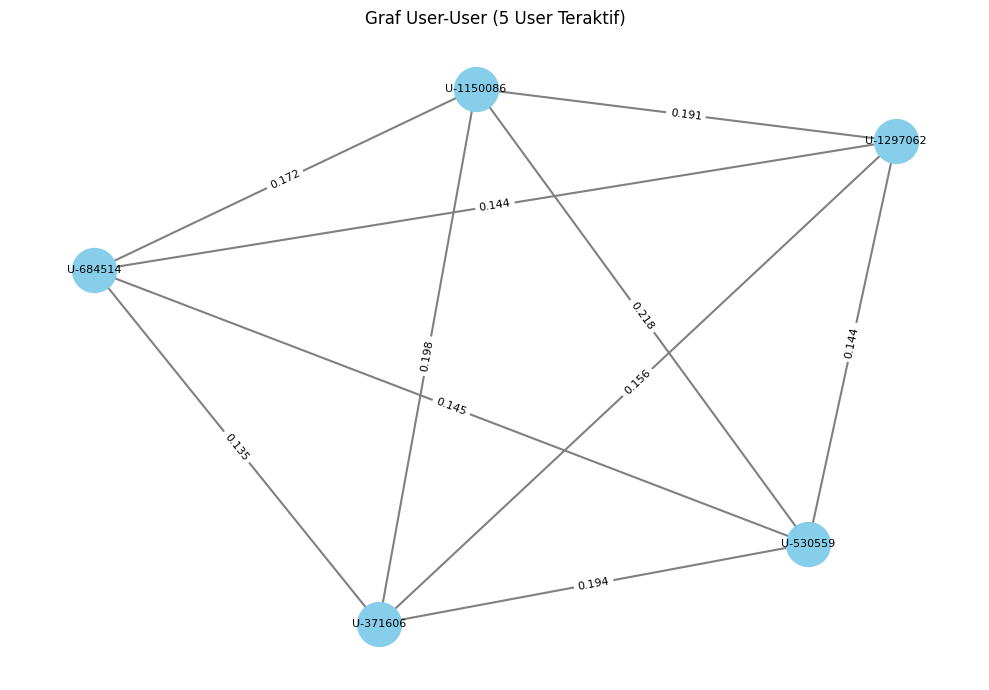

Node User pada graf: 5
Jumlah edge pada graf: 10


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize

# Membaca data training
df = pd.read_csv("P(1)_training.csv")
df = df.dropna(subset=["visitorid", "itemid"]).copy()
df["visitorid"] = df["visitorid"].astype(int)
df["itemid"] = df["itemid"].astype(int)

data_interaksi = df[["visitorid", "itemid"]].drop_duplicates()

# Membuat indeks seluruh User dan Item
user_ids = pd.Index(data_interaksi["visitorid"].unique())
item_ids = pd.Index(data_interaksi["itemid"].unique())
u_idx = user_ids.get_indexer(data_interaksi["visitorid"])
i_idx = item_ids.get_indexer(data_interaksi["itemid"])

VSM_User_Item = csr_matrix(
    (np.ones(len(data_interaksi), dtype=np.float32), (u_idx, i_idx)),
    shape=(len(user_ids), len(item_ids))
)

VSM_normalisasi = normalize(VSM_User_Item, norm="l2", axis=1)

print("Shape VSM User-Item:", VSM_User_Item.shape)
print("Dimensi:", VSM_User_Item.ndim)
print("Jumlah User:", VSM_User_Item.shape[0])
print("Jumlah Item:", VSM_User_Item.shape[1])
print("Elemen bukan nol:", VSM_User_Item.nnz)

total_elemen = VSM_User_Item.shape[0] * VSM_User_Item.shape[1]
print(f"Kepadatan: {VSM_User_Item.nnz / total_elemen * 100:.6f}%")

memori = (
    VSM_User_Item.data.nbytes
    + VSM_User_Item.indices.nbytes
    + VSM_User_Item.indptr.nbytes
) / 1024**2
print(f"Memori sparse: {memori:.2f} MB")

user_aktif = data_interaksi["visitorid"].value_counts().head(5).index
indeks_user_aktif = user_ids.get_indexer(user_aktif)

VSM_User_User_plot = (
    VSM_normalisasi[indeks_user_aktif]
    @ VSM_normalisasi.T
)

kemiripan_nonzero = VSM_User_User_plot.nnz
print("Pasangan kemiripan bukan nol pada baris 5 user:", kemiripan_nonzero)

VSM_5_User = VSM_normalisasi[indeks_user_aktif]
kemiripan_5_user = (VSM_5_User @ VSM_5_User.T).toarray()

G_user = nx.Graph()
G_user.add_nodes_from([f"U-{u}" for u in user_aktif])

for i in range(len(user_aktif)):
    for j in range(i + 1, len(user_aktif)):
        nilai = kemiripan_5_user[i, j]
        if nilai > 0:
            G_user.add_edge(
                f"U-{user_aktif[i]}",
                f"U-{user_aktif[j]}",
                weight=float(nilai)
            )

# Visualisasi graf 5 user teraktif
pos = nx.spring_layout(G_user, seed=42, weight="weight")

plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(
    G_user, pos, node_color="skyblue", node_size=1000
)
nx.draw_networkx_edges(
    G_user, pos, edge_color="gray", width=1.5
)
nx.draw_networkx_labels(G_user, pos, font_size=8)

label_edge = {
    (u, v): f"{data['weight']:.3f}"
    for u, v, data in G_user.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G_user, pos, edge_labels=label_edge, font_size=8
)

plt.title("Graf User-User (5 User Teraktif)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Node User pada graf:", G_user.number_of_nodes())
print("Jumlah edge pada graf:", G_user.number_of_edges())


VSM User–User dibentuk berdasarkan matriks interaksi User–Item dari seluruh data training. Setiap baris merepresentasikan user dan setiap kolom merepresentasikan item, dengan nilai 1 menunjukkan adanya interaksi antara user dan item. Matriks tersebut kemudian dinormalisasi menggunakan normalisasi L2 untuk menghitung kemiripan antaruser dengan metode cosine similarity.

user - item

Shape VSM User: (680434, 170160)
Dimensi: 2
Jumlah User: 680434
Jumlah Item: 170160
Elemen bukan nol: 1021307
Kepadatan: 0.000882%
Memori sparse: 7.47 MB


C:\Users\lenovo\AppData\Local\Temp\ipykernel_24116\54249976.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


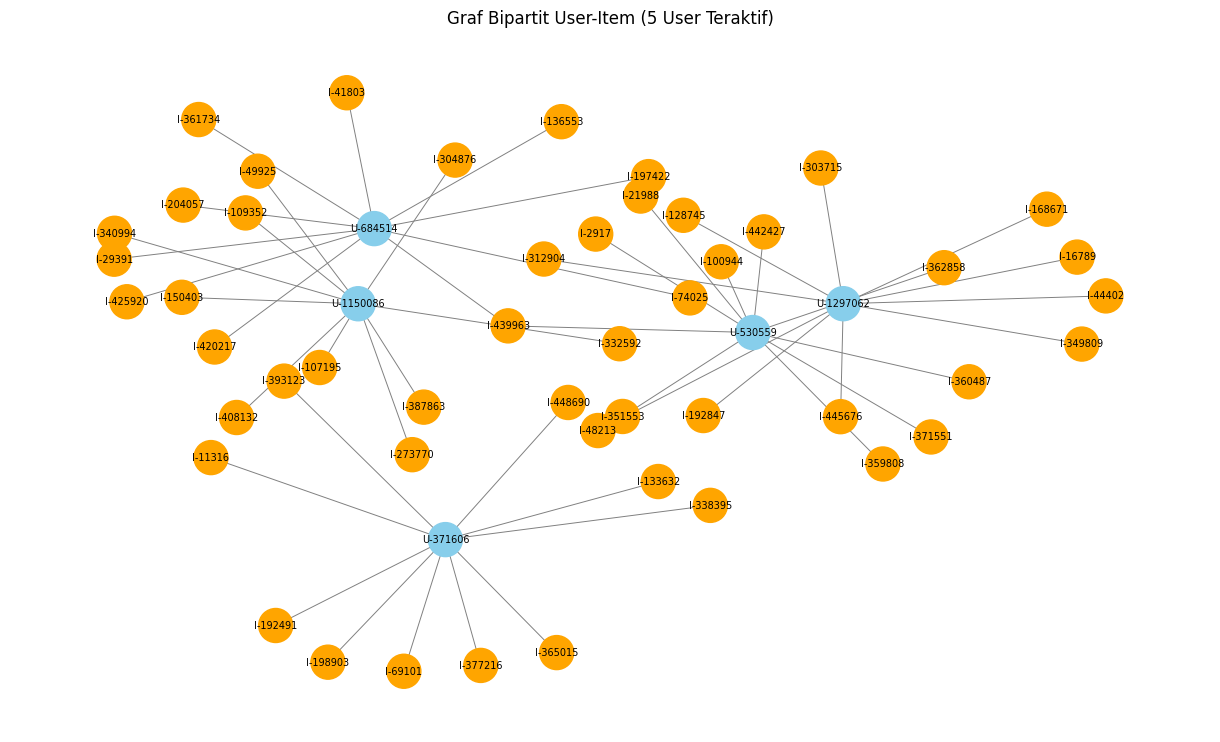

Node User: 5
Node Item: 49
Jumlah edge: 50


In [20]:
df = df.dropna(subset=["visitorid", "itemid"]).copy()
df["visitorid"] = df["visitorid"].astype(int)
df["itemid"] = df["itemid"].astype(int)

data_interaksi = df[["visitorid", "itemid"]].drop_duplicates()

user_ids = pd.Index(data_interaksi["visitorid"].unique())
item_ids = pd.Index(data_interaksi["itemid"].unique())
u_idx = user_ids.get_indexer(data_interaksi["visitorid"])
i_idx = item_ids.get_indexer(data_interaksi["itemid"])

VSM_User = csr_matrix(
    (np.ones(len(data_interaksi), dtype=np.int8), (u_idx, i_idx)),
    shape=(len(user_ids), len(item_ids))
)

print("Shape VSM User:", VSM_User.shape)
print("Dimensi:", VSM_User.ndim)
print("Jumlah User:", VSM_User.shape[0])
print("Jumlah Item:", VSM_User.shape[1])
print("Elemen bukan nol:", VSM_User.nnz)
total_elemen = VSM_User.shape[0] * VSM_User.shape[1]
print(f"Kepadatan: {VSM_User.nnz / total_elemen * 100:.6f}%")
print(f"Memori sparse: {(VSM_User.data.nbytes + VSM_User.indices.nbytes + VSM_User.indptr.nbytes) / 1024**2:.2f} MB")

user_aktif = data_interaksi["visitorid"].value_counts().head(5).index
data_plot = data_interaksi[data_interaksi["visitorid"].isin(user_aktif)]
data_plot = data_plot.groupby("visitorid", group_keys=False).head(10)

G_user = nx.Graph()
G_user.add_nodes_from([f"U-{u}" for u in user_aktif], bipartite="user")
G_user.add_nodes_from([f"I-{i}" for i in data_plot["itemid"].unique()], bipartite="item")
G_user.add_edges_from(
    (f"U-{u}", f"I-{i}")
    for u, i in data_plot.itertuples(index=False, name=None)
)

# Visualisasi graf
pos = nx.spring_layout(G_user, seed=42, iterations=10)
warna = [
    "skyblue" if G_user.nodes[n]["bipartite"] == "user" else "orange"
    for n in G_user.nodes()
]

plt.figure(figsize=(12, 7))
nx.draw(
    G_user, pos, with_labels=True, node_color=warna,
    node_size=600, font_size=7, edge_color="gray", width=0.7
)
plt.title("Graf Bipartit User-Item (5 User Teraktif)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Node User:", len([n for n in G_user if n.startswith("U-")]))
print("Node Item:", len([n for n in G_user if n.startswith("I-")]))
print("Jumlah edge:", G_user.number_of_edges())

Matriks VSM User memiliki shape sebesar (680434, 170160) dan berdimensi 2, dengan 680.434 User sebagai baris dan 170.160 Item sebagai kolom. Matriks ini memiliki 1.021.307 elemen bukan nol yang merepresentasikan interaksi unik antara User dan Item.

Matriks disimpan menggunakan format Compressed Sparse Row (CSR) dengan kebutuhan memori sebesar 7,47 MB agar penyimpanan lebih efisien. Visualisasi NetworkX menampilkan graf bipartit yang terdiri dari lima User teraktif dan maksimal sepuluh Item per User. Node User berwarna biru muda, sedangkan node Item berwarna oranye. Edge menunjukkan interaksi antara User dan Item.

Matriks ini dapat digunakan sebagai dasar analisis kemiripan antar-User dan sistem rekomendasi berbasis collaborative filtering.

Kode user-user membentuk VSM User–Item dan menghitung kemiripan antaruser menggunakan cosine similarity. Graf yang dihasilkan merupakan proyeksi User–User, yaitu setiap simpul mewakili user dan setiap sisi menunjukkan kemiripan pola interaksi dua user berdasarkan item yang sama. Visualisasi dibatasi pada lima user teraktif, sedangkan perhitungan kemiripan untuk kelima user tersebut dilakukan terhadap seluruh user. Sementara itu, Kode User-item menggunakan VSM User–Item untuk memvisualisasikan hubungan interaksi secara langsung dalam graf bipartit, dengan simpul user dan item dibedakan berdasarkan warna serta sisi menunjukkan adanya interaksi antara user dan item. Kode 1 lebih sesuai untuk mengamati kemiripan perilaku antarpengguna, sedangkan Kode 2 lebih sesuai untuk menggambarkan pola interaksi pengguna dengan item.

#### **Soal 2.1 (No.5) Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai Item**

item - item

Shape VSM Item-User: (170160, 680434)
Dimensi: 2
Jumlah Item: 170160
Jumlah User: 680434
Elemen bukan nol: 1021307
Kepadatan: 0.000882%
Memori sparse: 5.52 MB


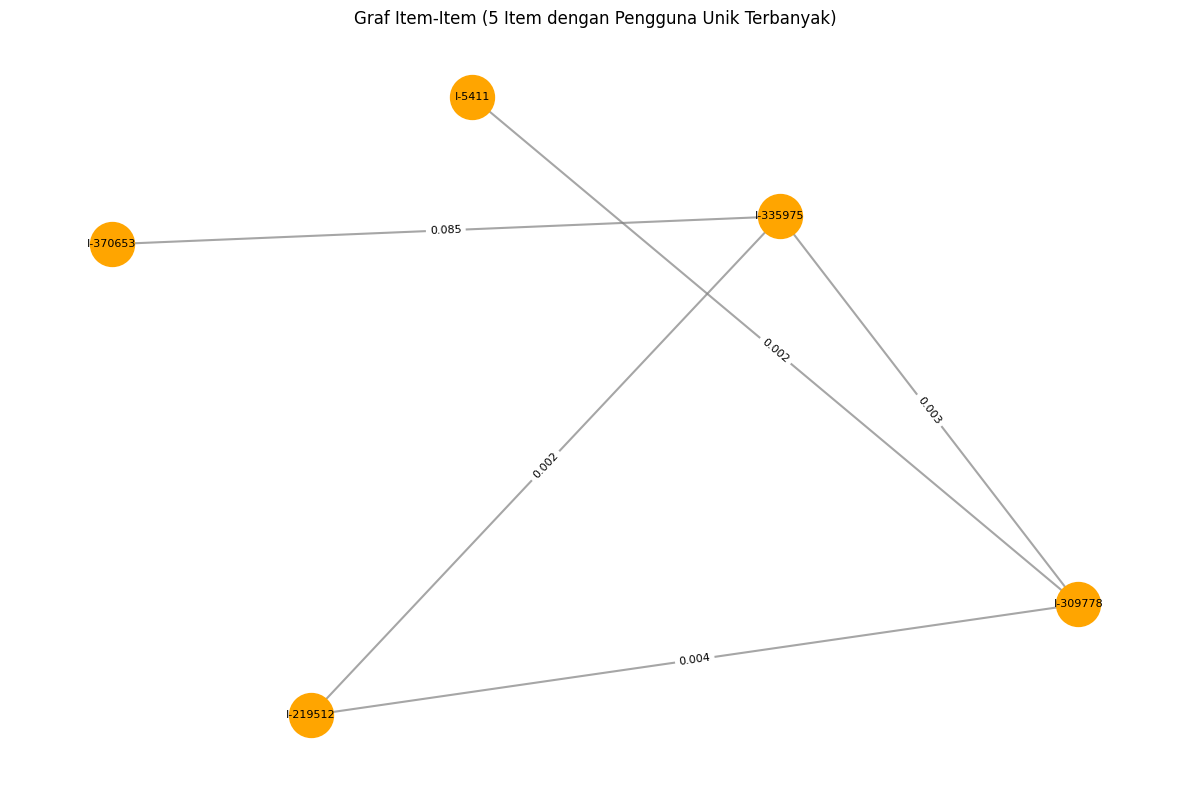

Node Item pada plot: 5
Jumlah edge pada plot: 5


In [21]:
from sklearn.preprocessing import normalize
VSM_Item_User = VSM_User.T.tocsr()
VSM_Item_normalisasi = normalize(VSM_Item_User, norm="l2", axis=1)

# Menampilkan karakteristik VSM Item-User
print("Shape VSM Item-User:", VSM_Item_User.shape)
print("Dimensi:", VSM_Item_User.ndim)
print("Jumlah Item:", VSM_Item_User.shape[0])
print("Jumlah User:", VSM_Item_User.shape[1])
print("Elemen bukan nol:", VSM_Item_User.nnz)

total_elemen = VSM_Item_User.shape[0] * VSM_Item_User.shape[1]
print(f"Kepadatan: {VSM_Item_User.nnz / total_elemen * 100:.6f}%")
memori = (
    VSM_Item_User.data.nbytes
    + VSM_Item_User.indices.nbytes
    + VSM_Item_User.indptr.nbytes
) / 1024**2
print(f"Memori sparse: {memori:.2f} MB")

# Memilih 5 item dengan jumlah pengguna unik terbanyak
item_populer = (
    data_interaksi.groupby("itemid")["visitorid"]
    .nunique()
    .nlargest(5)
    .index
)
indeks_item_populer = item_ids.get_indexer(item_populer)

# Menghitung cosine similarity antar 5 item terpopuler
VSM_5_Item = VSM_Item_normalisasi[indeks_item_populer]
kemiripan_5_item = (VSM_5_Item @ VSM_5_Item.T).toarray()

# Membuat graf Item-Item
G_item = nx.Graph()
G_item.add_nodes_from([f"I-{i}" for i in item_populer])

for i in range(len(item_populer)):
    for j in range(i + 1, len(item_populer)):
        nilai = kemiripan_5_item[i, j]
        if nilai > 0:
            G_item.add_edge(
                f"I-{item_populer[i]}",
                f"I-{item_populer[j]}",
                weight=float(nilai)
            )

pos = nx.spring_layout(G_item, seed=42, k=1.5, iterations=100)

plt.figure(figsize=(12, 8))
nx.draw_networkx_nodes(G_item, pos, node_color="orange", node_size=1000)
nx.draw_networkx_edges(G_item, pos, edge_color="gray", width=1.5, alpha=0.7)
nx.draw_networkx_labels(G_item, pos, font_size=8)

label_edge = {
    (u, v): f"{data['weight']:.3f}"
    for u, v, data in G_item.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G_item, pos, edge_labels=label_edge, font_size=8
)

plt.title("Graf Item-Item (5 Item dengan Pengguna Unik Terbanyak)")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Node Item pada plot:", G_item.number_of_nodes())
print("Jumlah edge pada plot:", G_item.number_of_edges())

Shape VSM Item: (170160, 680434)
Dimensi: 2
Jumlah Item: 170160
Jumlah User: 680434
Elemen bukan nol: 1021307
Kepadatan: 0.000882%
Memori sparse: 5.52 MB


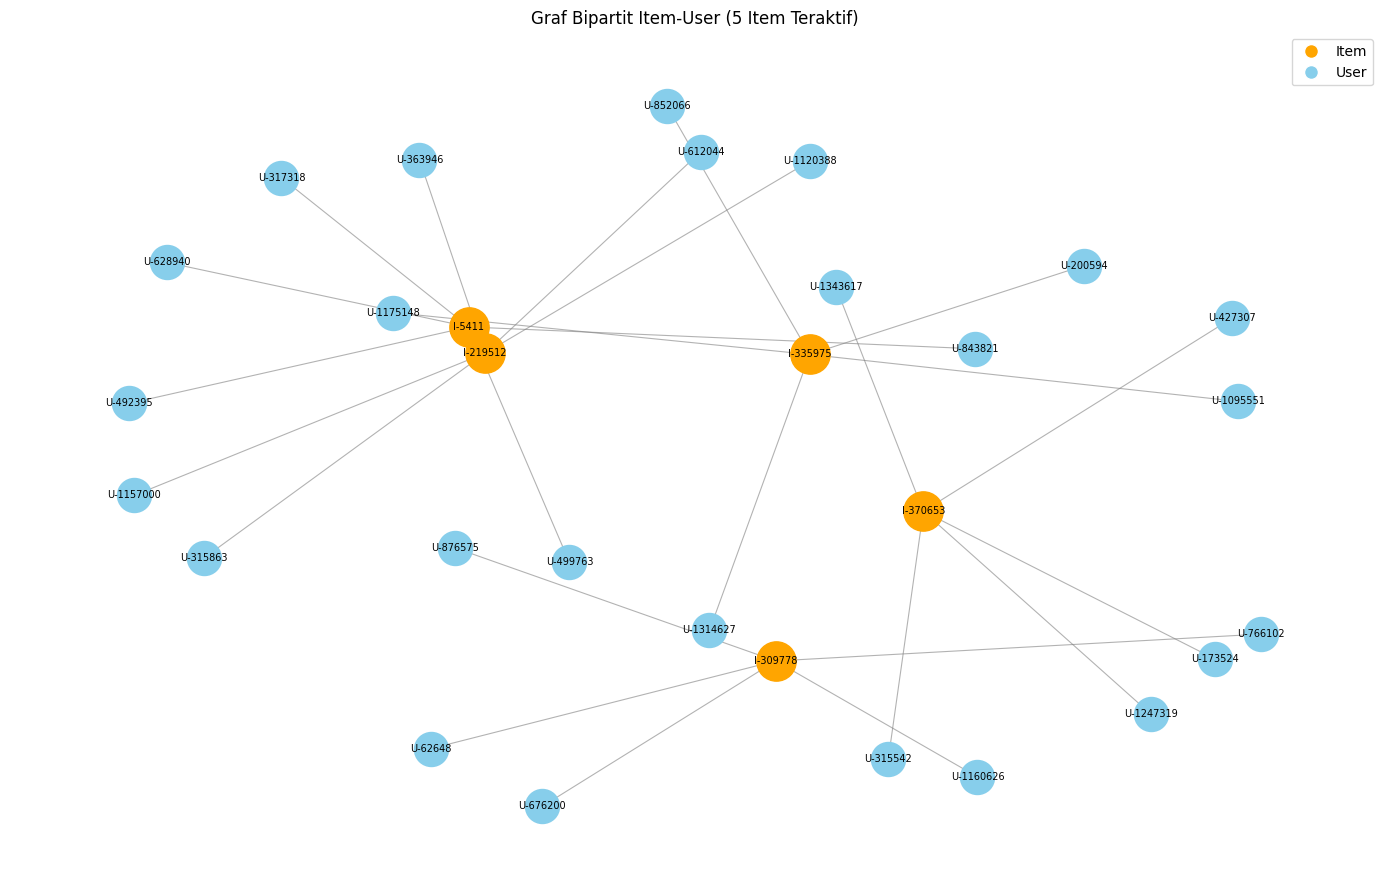

Node Item pada plot: 5
Node User pada plot: 25
Jumlah edge pada plot: 25


In [22]:
VSM_Item = VSM_User.T.tocsr()

print("Shape VSM Item:", VSM_Item.shape)
print("Dimensi:", VSM_Item.ndim)
print("Jumlah Item:", VSM_Item.shape[0])
print("Jumlah User:", VSM_Item.shape[1])
print("Elemen bukan nol:", VSM_Item.nnz)
total_elemen = VSM_Item.shape[0] * VSM_Item.shape[1]
print(f"Kepadatan: {VSM_Item.nnz / total_elemen * 100:.6f}%")
print(f"Memori sparse: {(VSM_Item.data.nbytes + VSM_Item.indices.nbytes + VSM_Item.indptr.nbytes) / 1024**2:.2f} MB")

# Memilih 5 Item dengan pengguna unik terbanyak
item_aktif = data_interaksi.groupby("itemid")["visitorid"].nunique().nlargest(5).index
data_plot_item = data_interaksi[data_interaksi["itemid"].isin(item_aktif)]
data_plot_item = data_plot_item.groupby("itemid", group_keys=False).head(5)

# Membuat graf bipartit Item-User
G_item = nx.Graph()
G_item.add_nodes_from([f"I-{i}" for i in item_aktif], bipartite="item")
G_item.add_nodes_from([f"U-{u}" for u in data_plot_item["visitorid"].unique()], bipartite="user")
G_item.add_edges_from(
    (f"I-{i}", f"U-{u}")
    for u, i in data_plot_item[["visitorid", "itemid"]].itertuples(index=False, name=None)
)

pos = nx.spring_layout(G_item, seed=42, k=1.5, iterations=100)
item_nodes = [n for n in G_item if n.startswith("I-")]
user_nodes = [n for n in G_item if n.startswith("U-")]

plt.figure(figsize=(14, 9))
nx.draw_networkx_nodes(G_item, pos, nodelist=item_nodes, node_color="orange", node_size=800)
nx.draw_networkx_nodes(G_item, pos, nodelist=user_nodes, node_color="skyblue", node_size=600)
nx.draw_networkx_edges(G_item, pos, edge_color="gray", width=0.8, alpha=0.6)
nx.draw_networkx_labels(G_item, pos, font_size=7)

plt.title("Graf Bipartit Item-User (5 Item Teraktif)")
plt.legend(handles=[
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="orange", markersize=10, label="Item"),
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="skyblue", markersize=10, label="User")
])
plt.axis("off")
plt.tight_layout()
plt.show()

print("Node Item pada plot:", len(item_nodes))
print("Node User pada plot:", len(user_nodes))
print("Jumlah edge pada plot:", G_item.number_of_edges())

Matriks VSM Item dibentuk dengan mentransposisi VSM User-Item sehingga baris merepresentasikan Item dan kolom merepresentasikan User. Matriks memiliki dimensi 2 dengan shape 170160, 680434. Jumlah elemen bukan nol dan kepadatannya sama dengan VSM User karena hanya terjadi pertukaran posisi baris dan kolom.

Visualisasi NetworkX menampilkan graf bipartit yang terdiri dari lima Item dengan pengguna unik terbanyak, maksimal lima User untuk setiap Item, serta 25 edge. Node Item berwarna oranye, sedangkan node User berwarna biru muda. Setiap edge menunjukkan interaksi antara User dan Item. Matriks ini dapat digunakan sebagai dasar analisis kemiripan antar-Item berdasarkan pola interaksi pengguna.

Kode item-item membentuk VSM Item–User melalui transpose VSM User–Item, kemudian menghitung cosine similarity antaritem berdasarkan kesamaan pengguna yang berinteraksi dengan item tersebut. Graf yang dihasilkan merupakan proyeksi Item–Item, dengan simpul mewakili item dan sisi berbobot menunjukkan tingkat kemiripan antaritem. Visualisasi dibatasi pada lima item dengan jumlah pengguna unik terbanyak. Sementara itu, Kode 4 menggunakan matriks Item–User untuk membentuk graf bipartit Item–User yang menggambarkan hubungan interaksi secara langsung antara item dan pengguna. Kode item-user lebih sesuai untuk menganalisis kemiripan antaritem, sedangkan Kode 4 lebih sesuai untuk menunjukkan pengguna yang berinteraksi dengan item tertentu. Oleh karena itu, pemilihan kode bergantung pada tujuan analisis, yaitu mempelajari kemiripan item atau menggambarkan hubungan interaksi item dengan pengguna.

#### **Soal 2.1 (No.6) Proyeksi yang Lebih Baik (efektif/efisien)**

In [23]:
def karakteristik_vsm(nama, matriks):
    memori = (
        matriks.data.nbytes
        + matriks.indices.nbytes
        + matriks.indptr.nbytes
    ) / 1024**2

    total_elemen = matriks.shape[0] * matriks.shape[1]

    return {
        "VSM": nama,
        "Shape": str(matriks.shape),
        "Dimensi": matriks.ndim,
        "Jumlah Baris": matriks.shape[0],
        "Jumlah Kolom": matriks.shape[1],
        "Elemen Bukan Nol": matriks.nnz,
        "Kepadatan (%)": matriks.nnz / total_elemen * 100,
        "Memori Sparse (MB)": memori
    }

VSM_Item = VSM_User.T.tocsr()

hasil_perbandingan = pd.DataFrame([
    karakteristik_vsm("VSM User-Item", VSM_User),
    karakteristik_vsm("VSM Item-User", VSM_Item)
])

display(hasil_perbandingan.round(6))


,VSM,Shape,Dimensi,Jumlah Baris,Jumlah Kolom,Elemen Bukan Nol,Kepadatan (%),Memori Sparse (MB)
0,VSM User-Item,"(680434, 170160)",2,680434,170160,1021307,0.000882,7.465625
1,VSM Item-User,"(170160, 680434)",2,170160,680434,1021307,0.000882,5.519084


Berdasarkan hasil perbandingan, VSM User memiliki shape (680434, 170160) dengan kebutuhan memori sebesar 7,47 MB, sedangkan VSM Item memiliki shape (170160, 680434) dengan kebutuhan memori sebesar 5,52 MB. Keduanya memiliki 1.021.307 elemen bukan nol dan kepadatan yang sama karena VSM Item merupakan transpose dari VSM User.

Dari segi efisiensi memori, VSM Item lebih efisien karena membutuhkan memori lebih kecil. Namun, dari segi kegunaan, pemilihan proyeksi bergantung pada tujuan analisis. VSM User lebih sesuai untuk menganalisis kemiripan antar-pengguna dan menghasilkan rekomendasi berdasarkan perilaku pengguna, sedangkan VSM Item lebih sesuai untuk menganalisis kemiripan antarproduk berdasarkan pola interaksi pengguna.

Dengan demikian, untuk analisis rekomendasi produk berdasarkan kemiripan antar-Item, VSM Item lebih relevan. Sementara itu, VSM User lebih tepat apabila tujuan utamanya adalah mencari pengguna dengan pola interaksi yang serupa.

#### **Soal 2.1 (No.7) Perhitungan Simmilarty**

a. 5 records dengan similarity tertinggi

In [24]:
kandidat_item = (
    data_interaksi.groupby("itemid")["visitorid"]
    .nunique()
    .reset_index(name="jumlah_pengguna_unik")
    .sort_values("jumlah_pengguna_unik", ascending=False)
    .reset_index(drop=True)
)

# Menambahkan peringkat item
kandidat_item.insert(
    0, "peringkat",
    range(1, len(kandidat_item) + 1)
)

display(kandidat_item.head(5))

,peringkat,itemid,jumlah_pengguna_unik
0,1,5411,1680
1,2,309778,689
2,3,219512,650
3,4,370653,630
4,5,335975,593


In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

item_acuan = 5411
indeks_acuan = np.where(np.asarray(item_ids, dtype=int) == item_acuan)[0][0]

nilai_similarity = cosine_similarity(VSM_Item[indeks_acuan], VSM_Item).ravel()
nilai_similarity[indeks_acuan] = -1

indeks_teratas = np.argsort(nilai_similarity)[-5:][::-1]

hasil_similarity = pd.DataFrame({
    "item_acuan": item_acuan,
    "item_mirip": [int(item_ids[i]) for i in indeks_teratas],
    "similarity": nilai_similarity[indeks_teratas]
})

display(hasil_similarity)

,item_acuan,item_mirip,similarity
0,5411,33030,0.156569
1,5411,33956,0.089188
2,5411,358234,0.080917
3,5411,37807,0.076447
4,5411,375492,0.070097


Berdasarkan hasil perhitungan cosine similarity, Item 5411 dipilih sebagai Item acuan karena memiliki jumlah pengguna terbanyak. Lima Item dengan tingkat kemiripan tertinggi adalah Item 33030 dengan nilai similarity 0,156569, Item 33956 sebesar 0,089188, Item 358234 sebesar 0,080917, Item 37807 sebesar 0,076447, dan Item 375492 sebesar 0,070097.

Item 33030 memiliki tingkat kemiripan tertinggi terhadap Item 5411, yaitu sebesar 0,156569. Hal ini menunjukkan bahwa pola interaksi pengguna terhadap kedua Item tersebut relatif lebih mirip dibandingkan empat Item lainnya dalam hasil perhitungan.

b. Menulis Nilai Similarity tersebut ke Graf

In [26]:
from neo4j import GraphDatabase

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
print("Koneksi Neo4j berhasil dibuka kembali.")

Koneksi Neo4j berhasil dibuka kembali.


In [27]:
query_simpan = """
MATCH (acuan:Item {itemId: $item_acuan})
MATCH (item_lain:Item {itemId: $item_mirip})
MERGE (acuan)-[r:SIMILAR_TO]->(item_lain)
SET r.similarity = $similarity
"""

with driver.session(database=DATABASE) as session:
    # Menghapus relasi similarity lama dari item acuan
    session.run("""
        MATCH (acuan:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->()
        DELETE r
    """, item_acuan=item_acuan)

    for _, baris in hasil_similarity.iterrows():
        session.run(
            query_simpan,
            item_acuan=int(baris["item_acuan"]),
            item_mirip=int(baris["item_mirip"]),
            similarity=float(baris["similarity"])
        )

query_hasil = """
MATCH (acuan:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->(item_lain:Item)
RETURN acuan.itemId AS item_acuan,
       item_lain.itemId AS item_mirip,
       r.similarity AS similarity
ORDER BY similarity DESC
LIMIT 5
"""

with driver.session(database=DATABASE) as session:
    hasil_graf = pd.DataFrame([
        record.data()
        for record in session.run(query_hasil, item_acuan=item_acuan)
    ])

display(hasil_graf)

,item_acuan,item_mirip,similarity
0,5411,33030,0.156569
1,5411,33956,0.089188
2,5411,358234,0.080917
3,5411,37807,0.076447
4,5411,375492,0.070097


Berdasarkan hasil eksekusi kode, lima nilai cosine similarity berhasil disimpan ke dalam graf Neo4j sebagai relasi SIMILAR_TO. Item 5411 menjadi Item acuan yang terhubung dengan lima Item lain, yaitu 33030, 33956, 358234, 37807, dan 375492. Setiap relasi menyimpan properti similarity yang menunjukkan tingkat kemiripan pola interaksi pengguna antara kedua Item.

Penggunaan perintah MERGE memastikan relasi dengan pasangan Item yang sama tidak dibuat berulang kali, sedangkan SET digunakan untuk menyimpan atau memperbarui nilai similarity. Dengan demikian, hasil perhitungan dari Python dapat dimanfaatkan langsung dalam graf Neo4j untuk menelusuri hubungan antar-Item dan mendukung rekomendasi produk berbasis kemiripan.

In [28]:
hasil_neo4j = pd.read_csv ("D:/TUGAS KAMPUS SEMESTER 7/GRAF SAINS DATA/UTS GRAF SAINS DATA/neo4j_query_table_data_Tahap 7.csv")
hasil_neo4j

,item_acuan,item_mirip,similarity
0,5411,33030,0.156569
1,5411,33956,0.089188
2,5411,358234,0.080917
3,5411,37807,0.076447
4,5411,375492,0.070097


#### **Soal 2.1 (No.8) : Visualisasi graf sebelum dan sesudah similarity**

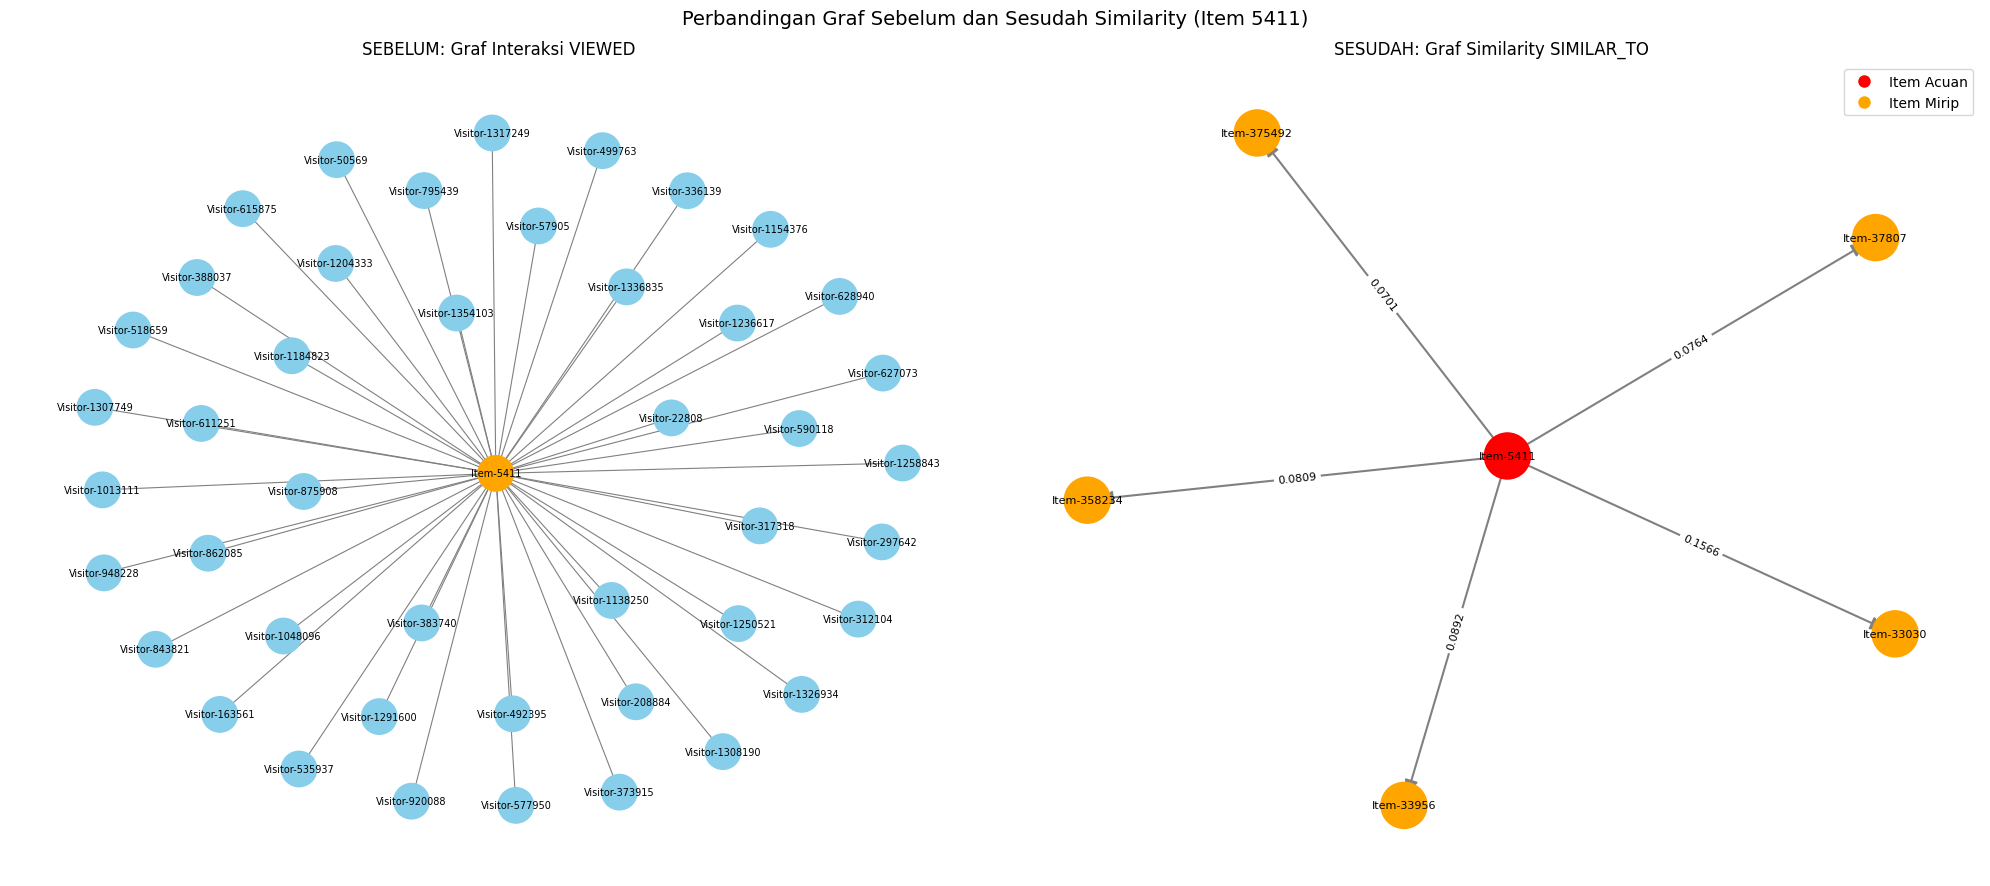

Jumlah relasi VIEWED yang ditampilkan: 50

Lima relasi SIMILAR_TO setelah similarity:


,item_acuan,item_mirip,similarity
0,5411,33030,0.156569
1,5411,33956,0.089188
2,5411,358234,0.080917
3,5411,37807,0.076447
4,5411,375492,0.070097


In [29]:
import networkx as nx
import matplotlib.pyplot as plt
from neo4j import GraphDatabase

ITEM_ACUAN = 5411
driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))

try:
    with driver.session(database=DATABASE) as session:
        # Graf sebelum similarity: mengambil 50 relasi VIEWED
        hasil_sebelum = session.run("""
            MATCH (v:Visitor)-[r:VIEWED]->(i:Item {itemId: $item_acuan})
            RETURN v.visitorId AS visitor, i.itemId AS item
            LIMIT 50
        """, item_acuan=ITEM_ACUAN).data()

        # Graf sesudah similarity: mengambil 5 relasi SIMILAR_TO
        hasil_sesudah = session.run("""
            MATCH (a:Item {itemId: $item_acuan})-[r:SIMILAR_TO]->(b:Item)
            RETURN a.itemId AS item_acuan,
                   b.itemId AS item_mirip,
                   r.similarity AS similarity
            ORDER BY r.similarity DESC
            LIMIT 5
        """, item_acuan=ITEM_ACUAN).data()
finally:
    driver.close()

# Membentuk graf sebelum similarity
G_sebelum = nx.Graph()
for baris in hasil_sebelum:
    G_sebelum.add_edge(
        f"Visitor-{baris['visitor']}",
        f"Item-{baris['item']}"
    )

G_sesudah = nx.DiGraph()
for baris in hasil_sesudah:
    G_sesudah.add_edge(
        f"Item-{baris['item_acuan']}",
        f"Item-{baris['item_mirip']}",
        similarity=baris["similarity"]
    )

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

pos_sebelum = nx.spring_layout(
    G_sebelum, seed=42, k=1.2, iterations=100
)
warna_sebelum = [
    "skyblue" if node.startswith("Visitor-") else "orange"
    for node in G_sebelum.nodes()
]

nx.draw(
    G_sebelum, pos_sebelum, ax=axes[0],
    with_labels=True, node_color=warna_sebelum,
    node_size=650, font_size=7,
    edge_color="gray", width=0.8
)
axes[0].set_title("SEBELUM: Graf Interaksi VIEWED")
axes[0].axis("off")

# Graf sesudah similarity
pos_sesudah = nx.spring_layout(
    G_sesudah, seed=42, k=1.5, iterations=100
)

warna_sesudah = [
    "red" if node == f"Item-{ITEM_ACUAN}" else "orange"
    for node in G_sesudah.nodes()
]

nx.draw_networkx_nodes(
    G_sesudah, pos_sesudah, ax=axes[1],
    node_color=warna_sesudah, node_size=1100
)
nx.draw_networkx_edges(
    G_sesudah, pos_sesudah, ax=axes[1],
    edge_color="gray", arrows=True,
    arrowsize=20, width=1.5
)
nx.draw_networkx_labels(
    G_sesudah, pos_sesudah, ax=axes[1], font_size=8
)

label_similarity = {
    (a, b): f"{data['similarity']:.4f}"
    for a, b, data in G_sesudah.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G_sesudah, pos_sesudah, ax=axes[1],
    edge_labels=label_similarity, font_size=8
)

axes[1].legend(handles=[
    plt.Line2D(
        [0], [0], marker="o", color="w",
        markerfacecolor="red", markersize=10,
        label="Item Acuan"
    ),
    plt.Line2D(
        [0], [0], marker="o", color="w",
        markerfacecolor="orange", markersize=10,
        label="Item Mirip"
    )
], loc="best")

axes[1].set_title("SESUDAH: Graf Similarity SIMILAR_TO")
axes[1].axis("off")

plt.suptitle(
    f"Perbandingan Graf Sebelum dan Sesudah Similarity (Item {ITEM_ACUAN})",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Jumlah relasi VIEWED yang ditampilkan:", len(hasil_sebelum))
print("\nLima relasi SIMILAR_TO setelah similarity:")

if hasil_sesudah:
    display(pd.DataFrame(hasil_sesudah))
else:
    print("Belum ada relasi SIMILAR_TO. Jalankan kode 7 terlebih dahulu.")

Berdasarkan visualisasi graf, sebelum perhitungan similarity, graf menunjukkan hubungan antara Visitor dan Item melalui relasi VIEWED. Graf ini menggambarkan pengguna yang pernah melihat Item 5411, sehingga dapat digunakan untuk memahami pola interaksi pengguna terhadap Item tersebut.

Setelah perhitungan cosine similarity, graf menunjukkan hubungan antara Item acuan 5411 dan lima Item yang memiliki kemiripan pola interaksi tertinggi melalui relasi SIMILAR_TO. Item acuan ditandai dengan warna merah, sedangkan Item yang mirip ditandai dengan warna oranye. Nilai similarity ditampilkan pada setiap relasi untuk menunjukkan tingkat kemiripan antar-Item.

Item 33030 memiliki nilai similarity tertinggi sebesar 0,156569, diikuti Item 33956 sebesar 0,089188, Item 358234 sebesar 0,080917, Item 37807 sebesar 0,076447, dan Item 375492 sebesar 0,070097. Hasil ini menunjukkan bahwa pola interaksi pengguna terhadap Item 33030 paling mirip dengan Item acuan 5411 dibandingkan empat Item lainnya.

Secara keseluruhan, visualisasi memperlihatkan perubahan graf dari hubungan interaksi pengguna terhadap produk menjadi hubungan kemiripan antarproduk. Relasi SIMILAR_TO dapat dimanfaatkan sebagai dasar rekomendasi Item berbasis kemiripan pola interaksi pengguna. Namun, nilai similarity yang relatif rendah menunjukkan bahwa tingkat kemiripan antar-Item tersebut masih terbatas. Kemiripan ini juga didasarkan pada pola interaksi pengguna, bukan pada kesamaan kategori, harga, atau karakteristik produk lainnya.

## **ANALYTICS**

#### **Soal 2.2 (No.1) KNN dengan K=5 dan item =3**

In [30]:
import numpy as np
import pandas as pd

# Memilih user secara acak dan reproducible
rng = np.random.default_rng(42)
indeks_user = int(rng.integers(0, VSM_User.shape[0]))

user_acuan = user_ids[indeks_user]
user_target = VSM_User.getrow(indeks_user)

print("User acuan:", user_acuan)
print("Jumlah item user acuan:", user_target.nnz)

# Menghitung cosine similarity dengan seluruh user
irisan = (user_target @ VSM_User.T).tocoo()

norm_user = np.sqrt(user_target.multiply(user_target).sum())
norm_semua_user = np.sqrt(
    np.asarray(VSM_User.multiply(VSM_User).sum(axis=1)).ravel()
)

valid = (
    (irisan.col != indeks_user) &
    (norm_semua_user[irisan.col] > 0)
)

indeks_tetangga = irisan.col[valid]
nilai_similarity = irisan.data[valid] / (
    norm_user * norm_semua_user[indeks_tetangga]
)

# Memilih 5 tetangga terdekat
urutan = np.argsort(nilai_similarity)[::-1][:5]
indeks_knn = indeks_tetangga[urutan]
similarity_knn = nilai_similarity[urutan]

hasil_knn = pd.DataFrame({
    "visitorId": user_ids[indeks_knn],
    "similarity": similarity_knn
})

print("\nLima tetangga terdekat (KNN):")
display(hasil_knn)

# Menghitung skor rekomendasi item berdasarkan 5 tetangga
interaksi_tetangga = VSM_User[indeks_knn]

skor_item = np.asarray(
    interaksi_tetangga.multiply(
        similarity_knn.reshape(-1, 1)
    ).sum(axis=0)
).ravel()

skor_item[user_target.indices] = 0

indeks_kandidat = np.where(skor_item > 0)[0]
urutan_rekomendasi = np.argsort(
    skor_item[indeks_kandidat]
)[::-1][:3]
indeks_rekomendasi = indeks_kandidat[urutan_rekomendasi]

hasil_rekomendasi = pd.DataFrame({
    "itemId": item_ids[indeks_rekomendasi],
    "skor_rekomendasi": skor_item[indeks_rekomendasi]
})

print("\nTiga item rekomendasi untuk k = 5:")
if len(hasil_rekomendasi) > 0:
    display(hasil_rekomendasi)
else:
    print("Tidak ditemukan item rekomendasi yang memenuhi kriteria.")

# Memeriksa jumlah kandidat rekomendasi
print("\nJumlah kandidat item rekomendasi:", len(indeks_kandidat))

User acuan: 15400
Jumlah item user acuan: 2

Lima tetangga terdekat (KNN):


,visitorId,similarity
0,816829,0.707107
1,958825,0.707107
2,604074,0.707107
3,120457,0.707107
4,1266139,0.707107



Tiga item rekomendasi untuk k = 5:
Tidak ditemukan item rekomendasi yang memenuhi kriteria.

Jumlah kandidat item rekomendasi: 0


In [31]:
print("Jumlah skor item positif:", np.sum(skor_item > 0))
print("Jumlah item dengan skor nol:", np.sum(skor_item == 0))
print("Jumlah item dengan skor negatif:", np.sum(skor_item < 0))

Jumlah skor item positif: 0
Jumlah item dengan skor nol: 170160
Jumlah item dengan skor negatif: 0


Berdasarkan hasil KNN dengan \(k=5\), user acuan 15400 berhasil memperoleh lima tetangga terdekat, yaitu 816829, 958825, 604074, 120457, dan 1266139. Nilai cosine similarity masing-masing tetangga adalah 0,707107. Nilai yang sama menunjukkan bahwa kelima tetangga memiliki tingkat kemiripan yang setara dengan user acuan berdasarkan pola interaksi pada data yang digunakan.

Pada tahap rekomendasi, sistem mengecualikan item yang telah diakses oleh user acuan dan menghitung skor rekomendasi berdasarkan interaksi kelima tetangga yang dibobot menggunakan nilai cosine similarity. Namun, hasil perhitungan menunjukkan bahwa tidak terdapat item dengan skor rekomendasi positif. Dari total 170.160 item, seluruhnya memiliki skor nol setelah item yang telah diakses user acuan dikecualikan. Oleh karena itu, sistem belum dapat menghasilkan item rekomendasi untuk user acuan 15400 pada pengujian dengan (k=5).

#### **Soal No 2.2 (No.2) Hasil Hit@5 dan NDCG@5**

In [32]:
# User acuan dari hasil Analytics nomor 1(b)
user_acuan = 15400

# Mengambil interaksi aktual user dari dataset
df_interaksi = pd.read_csv("P(1)_training.csv")
item_aktual = set(
    df_interaksi.loc[
        df_interaksi["visitorid"] == user_acuan, "itemid"
    ].dropna().astype(int)
)

# Mengambil maksimal 5 item rekomendasi
item_rekomendasi = (
    hasil_rekomendasi["itemId"].astype(int).tolist()[:5]
)

# Menentukan relevansi setiap item
relevansi = [
    1 if item in item_aktual else 0
    for item in item_rekomendasi
]

# (a) Hit@5: bernilai 1 jika ada item relevan di top-5
hit_at_5 = int(sum(relevansi) > 0)

# (b) NDCG@5
def hitung_dcg(relevansi):
    return sum(
        nilai / np.log2(posisi + 2)
        for posisi, nilai in enumerate(relevansi)
    )

dcg = hitung_dcg(relevansi)
ideal = sorted(relevansi, reverse=True)
idcg = hitung_dcg(ideal)
ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print("User acuan:", user_acuan)
print("Item rekomendasi:", item_rekomendasi)
print("Relevansi:", relevansi)
print("Hit@5:", hit_at_5)
print("NDCG@5:", round(ndcg_at_5, 4))

User acuan: 15400
Item rekomendasi: []
Relevansi: []
Hit@5: 0
NDCG@5: 0.0


Berdasarkan hasil evaluasi pada User 15400, daftar rekomendasi masih kosong sehingga Hit@5 bernilai 0 dan NDCG@5 bernilai 0,0. Hal ini terjadi karena sistem belum menghasilkan Item rekomendasi yang dapat dibandingkan dengan interaksi aktual pengguna. Oleh karena itu, nilai evaluasi tersebut menunjukkan bahwa belum ada rekomendasi relevan yang berhasil ditemukan pada pengujian ini, bukan berarti seluruh kinerja model KNN buruk.